# 01 — Comprendre les données PPMI (analyse exploratoire)

**But.** Regarder les données **avant** de les transformer. 

Chaque section suit le même schéma :

| Étape | Question |
|---|---|
| **Observation** | Que voit-on dans les données ? |
| **Décision** | Que fait-on dans le nettoyage (`02_nettoyage.ipynb`) ? |
| **Pour les modèles** | Quelle conséquence pour les statistiques et le deep learning ? |

**Plan.**

1. Les sources de données
2. Qui étudier ? (population)
3. Une étude longitudinale : visites, suivi, abandons
4. La variable cible : MDS-UPDRS partie III
5. Comment le score évolue
6. Les autres modalités et les autres échelles
7. Données manquantes et abandons
8. Synthèse : des observations aux décisions

> Les données PPMI sont sous accord d'utilisation : les sorties de ce notebook ne sont **jamais** commitées

In [1]:
# Configuration : chemins du projet, style des figures, graine aléatoire
import os, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(os.environ.get("PPMI_PROJECT_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from parkinson_mm import visualization as viz
from parkinson_mm.utils.config import load_config
from parkinson_mm.utils.env import set_seed
from parkinson_mm.data.io import load_tables, parse_month, months_between
from parkinson_mm.data.inventory import inventory
from parkinson_mm.data.updrs3_items import ALL_ITEMS, UNRATABLE

cfg = load_config(ROOT / "params.yaml")
RAW, SEED = cfg.path("raw"), cfg.project.seed
FIG = cfg.path("reports") / "figures" / "eda"; FIG.mkdir(parents=True, exist_ok=True)
TAB = cfg.path("reports") / "tables" / "eda"; TAB.mkdir(parents=True, exist_ok=True)
set_seed(SEED); viz.set_style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 180)

T = load_tables(RAW)          # toutes les tables PPMI utiles, lues une seule fois
print("Tables chargées :", ", ".join(T))

Tables chargées : status, demographics, age, socio, family, updrs1, updrs1p, updrs2, updrs3, updrs4, schwab, datscan, mri_aseg, genetics, prs, biospecimen, pd_dx_history, ledd, moca, ess, gds, scopa, stai


## 1. Les sources de données

**Pourquoi.** Avant tout calcul, il faut savoir ce que contient chaque fichier : combien de lignes, de patients
(`PATNO`), de visites (`EVENT_ID`), et à quel **grain** il est (une ligne par patient, ou par patient et par visite ?).

In [2]:
inv = inventory(RAW)
inv.sort_values(["dossier", "fichier"]).reset_index(drop=True)

,dossier,fichier,lignes,colonnes,patients,visites,manquants_pct
0,(racine),Family_History_04Oct2026.csv,9145,43,8214,7.0,32.7
1,(racine),Participant_Status_04Oct2026.csv,9304,35,9304,NaN,10.7
2,Biospecimen_Analysis,Current_Biospecimen_Analysis_Results_07Oct2026...,1157197,13,2966,NaN,1.4
3,DaTSCAN,Xing_Core_Lab_-_Quant_SBR_04Oct2026.csv,10510,42,4795,23.0,5.1
4,Genetic_Status,Polygenic_Risk_Scores_04Oct2026.csv,2996,17,2996,NaN,0.0
5,Genetic_Status,iu_genetic_consensus_20251025_04Oct2026.csv,6265,21,6265,NaN,18.0
6,MR_Analysis_Results,FS7_ASEG_VOL_04Oct2026.csv,1713,66,1713,1.0,0.0
7,Medical,LEDD_Concomitant_Medication_Log_07Oct2026.csv,10255,15,1874,2.0,21.6
8,Medical,PD_Diagnosis_History_07Oct2026.csv,2253,15,2253,3.0,0.1
9,Motor___MDS-UPDRS,MDS-UPDRS_Part_III_04Oct2026.csv,39996,65,5470,43.0,26.1


In [3]:
# Le grain de chaque table : la clé (patient, visite) est-elle unique ?
def grain(name, df):
    key = ["PATNO", "EVENT_ID"] if "EVENT_ID" in df else ["PATNO"]
    return {"table": name, "lignes": len(df), "patients": df.PATNO.nunique(),
            "clé": " + ".join(key), "doublons": int(df.duplicated(key).sum())}

pd.DataFrame([grain(k, v) for k, v in T.items() if "PATNO" in v])

,table,lignes,patients,clé,doublons
0,status,9304,9304,PATNO,0
1,demographics,9253,9253,PATNO + EVENT_ID,0
2,age,51008,8993,PATNO + EVENT_ID,474
3,socio,9157,8246,PATNO + EVENT_ID,0
4,family,9145,8214,PATNO + EVENT_ID,0
5,updrs1,33830,5464,PATNO + EVENT_ID,0
6,updrs1p,38719,5465,PATNO + EVENT_ID,0
7,updrs2,38720,5465,PATNO + EVENT_ID,0
8,updrs3,39996,5470,PATNO + EVENT_ID,7055
9,updrs4,11322,1792,PATNO + EVENT_ID,0


**Observation.** Les tables sont au grain *patient* ou *patient × visite*. La table du MDS-UPDRS III a des
**doublons** sur (patient, visite) : un patient peut avoir plusieurs examens moteurs à la même visite.

**Décision D1.** Comprendre ces doublons (section 4.2) avant de joindre les tables, sinon une jointure multiplierait
les lignes.

## 2. Qui étudier ? (population)

**Pourquoi.** PPMI contient plusieurs cohortes. Notre question porte sur l'évolution de la maladie de Parkinson :
il faut choisir les bons participants.

ENROLL_STATUS,Baseline,Baseline Withdraw,Complete,Declined,Enrolled,Excluded,Pending,Screen Scheduled,Screen failed,Screened,Withdraw Deceased,Withdrew
COHORT_DEFINITION,,,,,,,,,,,,
Healthy Control,0,1,11,14,223,35,0,0,55,0,7,94
Parkinson's Disease,14,22,34,47,1301,76,5,1,382,2,61,312
Prodromal,25,31,6,40,2763,157,161,8,2896,189,24,209
SWEDD,0,0,50,14,1,3,0,0,0,0,0,13


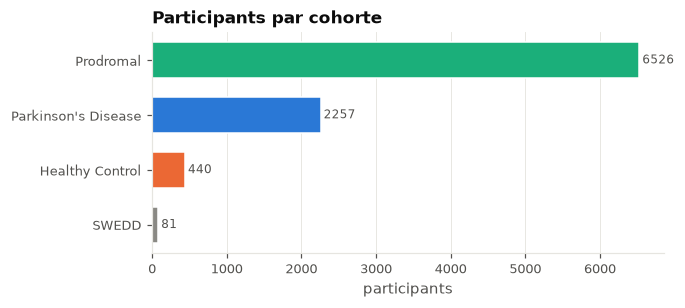

In [4]:
st = T["status"]
display(st.groupby(["COHORT_DEFINITION", "ENROLL_STATUS"]).size().unstack(fill_value=0))

counts = st["COHORT_DEFINITION"].value_counts()
fig, ax = plt.subplots(figsize=(6, 2.6))
viz.bar(ax, counts.index[::-1], counts.values[::-1], horizontal=True,
        color=[viz.COHORT_COLORS.get(c, viz.MUTED) for c in counts.index[::-1]])
ax.set_title("Participants par cohorte"); ax.set_xlabel("participants")
viz.save(fig, FIG, "02_cohortes"); plt.show()

**Observation.** La base contient surtout des participants *prodromaux*. Une partie des patients Parkinson n'a
jamais été incluse (échec de sélection, refus) : ils n'ont aucune visite de suivi.

**Décision D2.** Population = patients de la cohorte *Parkinson's Disease* **réellement inclus**. Les patients qui
ont quitté l'étude sont **gardés** : leurs visites passées sont valides, et les retirer donnerait une image trop
optimiste de la maladie (biais du survivant).

In [5]:
ENROLLED = ["Enrolled", "Withdrew", "Withdraw Deceased", "Complete", "Baseline", "Baseline Withdraw"]
pd_ids = st.loc[st.COHORT_DEFINITION.eq("Parkinson's Disease") & st.ENROLL_STATUS.isin(ENROLLED), "PATNO"]
print(f"Patients Parkinson inclus : {pd_ids.nunique()}")

Patients Parkinson inclus : 1744


### Tableau 1 : caractéristiques à l'inclusion

Description adaptée à la distribution : moyenne ± écart-type si la variable est à peu près symétrique, sinon médiane
[IQR]. Les tests (Kruskal-Wallis, χ²) sont **descriptifs** : ils ne servent pas à conclure.

In [6]:
# Examens moteurs de tous les participants (réutilisés dans les sections suivantes)
u3 = T["updrs3"].copy()
u3["np3"] = pd.to_numeric(u3["NP3TOT"], errors="coerce")
u3["nhy"] = pd.to_numeric(u3["NHY"], errors="coerce").where(lambda s: s <= 5)
u3["state"] = np.select([u3.PDTRTMNT.eq(0).to_numpy(), u3.PDSTATE.eq("OFF").fillna(False).to_numpy(bool),
                         u3.PDSTATE.eq("ON").fillna(False).to_numpy(bool)], ["untreated", "OFF", "ON"], "unknown")
u3["date"] = parse_month(u3["INFODT"])
RANG = {"untreated": 0, "OFF": 1, "ON": 2, "unknown": 3}       # priorité : sans traitement > OFF > ON
bl = (u3[u3.EVENT_ID.isin(["BL", "SC"]) & u3.np3.notna()]
      .assign(rang=lambda d: d.state.map(RANG) + 10 * d.EVENT_ID.eq("SC"))
      .sort_values(["PATNO", "rang"]).drop_duplicates("PATNO")[["PATNO", "np3", "nhy"]])

base = (st[["PATNO", "COHORT_DEFINITION", "ENROLL_AGE"]]
        .merge(T["demographics"][["PATNO", "SEX"]].drop_duplicates("PATNO"), on="PATNO", how="left")
        .merge(T["family"].groupby("PATNO", as_index=False).ANYFAMPD.max(), on="PATNO", how="left")
        .merge(bl, on="PATNO", how="left"))
base = base[base.COHORT_DEFINITION.isin(["Parkinson's Disease", "Healthy Control", "Prodromal"])
            & base.PATNO.isin(st.loc[st.ENROLL_STATUS.isin(ENROLLED), "PATNO"])]

def describe(x):
    x = x.dropna()
    if len(x) < 3: return "—"
    return f"{x.mean():.1f} ± {x.std():.1f}" if abs(stats.skew(x)) < 1 else \
           f"{x.median():.1f} [{x.quantile(.25):.1f}–{x.quantile(.75):.1f}]"

rows = {}
for var, label in [("ENROLL_AGE", "Âge (ans)"), ("np3", "MDS-UPDRS III"), ("nhy", "Hoehn & Yahr")]:
    rows[label] = {c: describe(g[var]) for c, g in base.groupby("COHORT_DEFINITION")}
    groups = [g[var].dropna() for _, g in base.groupby("COHORT_DEFINITION") if g[var].notna().sum() > 5]
    rows[label]["p"] = f"{stats.kruskal(*groups).pvalue:.1e}" if len(groups) > 1 else "—"
for var, label in [("SEX", "Hommes (%)"), ("ANYFAMPD", "Antécédent familial (%)")]:
    rows[label] = {c: f"{100 * g[var].mean():.0f}" for c, g in base.groupby("COHORT_DEFINITION")}
    rows[label]["p"] = f"{stats.chi2_contingency(pd.crosstab(base.COHORT_DEFINITION, base[var])).pvalue:.1e}"
table1 = pd.DataFrame(rows).T
table1.columns = [f"{c} (n={(base.COHORT_DEFINITION == c).sum()})" if c != "p" else c for c in table1.columns]
table1.to_csv(TAB / "03_tableau1.csv"); table1

,Healthy Control (n=336),Parkinson's Disease (n=1744),Prodromal (n=3058),p
Âge (ans),62.1 ± 11.4,63.4 ± 10.0,67.1 ± 6.9,2.3e-38
MDS-UPDRS III,0.0 [0.0–2.0],22.8 ± 11.0,3.0 [1.0–6.0],0.0e+00
Hoehn & Yahr,0.0 [0.0–0.0],1.7 ± 0.5,0.0 [0.0–0.0],0.0e+00
Hommes (%),59,61,48,1.7e-17
Antécédent familial (%),11,42,44,6.5e-23


## 3. Une étude longitudinale : visites, suivi, abandons

**Pourquoi.** Nos données sont **répétées dans le temps** : il faut connaître le rythme des visites, la durée de suivi
et le nombre de patients qui quittent l'étude, car tout cela conditionne le choix des modèles.

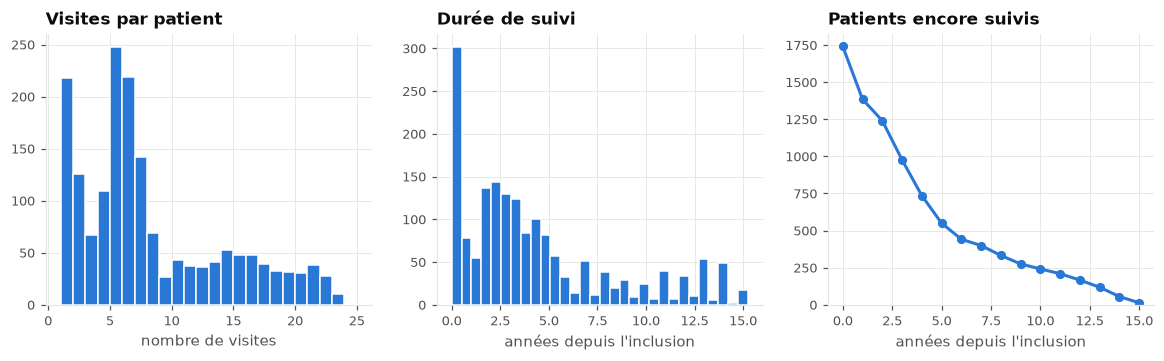

,count,mean,std,min,25%,50%,75%,max
visites,1740.0,7.8,5.9,1.0,4.0,6.0,11.2,24.0
suivi_ans,1740.0,4.3,4.0,0.0,1.6,3.1,6.0,15.2


In [7]:
# Examens des patients Parkinson, avec le temps depuis l'inclusion
u = u3[u3.PATNO.isin(pd_ids)].copy()
bl_date = u[u.EVENT_ID.eq("BL")].groupby("PATNO").date.min()
u["bl"] = u.PATNO.map(bl_date).fillna(u.PATNO.map(u.groupby("PATNO").date.min()))
u["months"] = months_between(u["bl"], u["date"])

calendrier = (u[u.np3.notna()].groupby("EVENT_ID")
              .agg(examens=("np3", "size"), patients=("PATNO", "nunique"), mois_median=("months", "median"))
              .sort_values("mois_median"))
calendrier.to_csv(TAB / "04_calendrier_visites.csv")

valid = u[u.np3.notna() & ~u.EVENT_ID.str.startswith("R")]          # examens réellement faits sur place
per_pat = valid.groupby("PATNO").agg(visites=("date", "nunique"), suivi_ans=("months", lambda s: s.max() / 12))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(per_pat.visites, bins=range(1, per_pat.visites.max() + 2), color=viz.C["blue"], edgecolor="white")
axes[0].set_title("Visites par patient"); axes[0].set_xlabel("nombre de visites")
axes[1].hist(per_pat.suivi_ans, bins=30, color=viz.C["blue"], edgecolor="white")
axes[1].set_title("Durée de suivi"); axes[1].set_xlabel("années depuis l'inclusion")
years = np.arange(0, 16)
axes[2].plot(years, [(per_pat.suivi_ans >= y).sum() for y in years], marker="o", color=viz.C["blue"])
axes[2].set_ylim(0); axes[2].set_title("Patients encore suivis"); axes[2].set_xlabel("années depuis l'inclusion")
viz.save(fig, FIG, "04_structure_longitudinale"); plt.show()
per_pat.describe().round(1).T

**Observation.**

* Les visites sont **irrégulières** : tous les 3 mois la première année, puis tous les 6 ou 12 mois.
* Le nombre de visites varie beaucoup d'un patient à l'autre.
* Beaucoup de patients quittent l'étude avec le temps (**attrition**), et les patients récents ont un suivi court.

**Décisions D4 et D5.** Le temps est une variable **continue** (années depuis l'inclusion), pas un numéro de visite.

**Pour les modèles.** Les **modèles à effets mixtes** gèrent naturellement un nombre de visites différent par
patient. Pour les réseaux, l'écart de temps entre visites est une entrée (le GRU-D l'utilise pour « oublier »
les mesures anciennes).

## 4. La variable cible : MDS-UPDRS partie III

### 4.1 Qualité du score

**Pourquoi.** Le score total (0 à 132) est la somme de 33 items cotés de 0 à 4. Il faut vérifier les codes spéciaux
et les totaux manquants.

In [8]:
items = u[ALL_ITEMS].apply(pd.to_numeric, errors="coerce")
n_valid = items.mask(items > 4).notna().sum(axis=1)          # items valides par examen (101 exclu)
pd.Series({
    "examens Parkinson": len(u),
    "items codés 101 (« non évaluable »)": int((items == UNRATABLE).sum().sum()),
    "total manquant": int(u.np3.isna().sum()),
    "… dont visites à distance (R##)": int((u.np3.isna() & u.EVENT_ID.str.startswith("R")).sum()),
    "total manquant mais récupérable (≥ 30 items valides)": int((u.np3.isna() & n_valid.ge(30)).sum()),
    "total hors de [0, 132]": int((~u.np3.dropna().between(0, 132)).sum()),
}).to_frame("examens")

,examens
examens Parkinson,21869
items codés 101 (« non évaluable »),10140
total manquant,3646
… dont visites à distance (R##),1611
total manquant mais récupérable (≥ 30 items valides),189
"total hors de [0, 132]",0


**Observation.** La valeur **101** veut dire « non évaluable » : ce n'est pas un score (un seul 101 ajouterait
101 points). Les visites à distance n'ont pas d'examen moteur.

**Décisions D6 et D7.** 101 → valeur manquante. Total recalculé si les 33 items sont valides, **proratisé** si au plus
3 items manquent, sinon examen rejeté. Visites à distance exclues.

### 4.2 Plusieurs examens à la même visite : l'effet du traitement (ON / OFF)

4338 paires OFF/ON à la même visite : écart moyen 9.5 points (médiane 8), OFF > ON dans 92 % des cas, Wilcoxon p = 0.0e+00


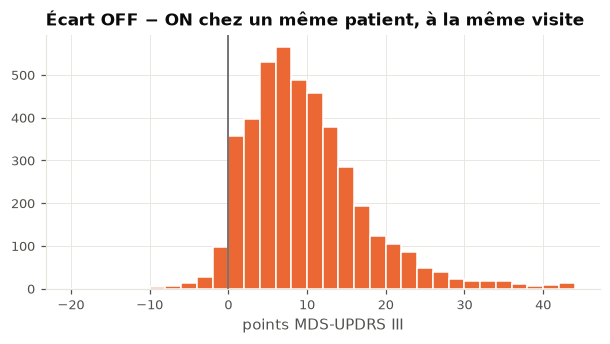

In [9]:
pair = (u[u.state.isin(["ON", "OFF"]) & u.np3.notna()]
        .groupby(["PATNO", "EVENT_ID", "state"]).np3.mean().unstack().dropna())
pair["ecart"] = pair["OFF"] - pair["ON"]
test = stats.wilcoxon(pair["OFF"], pair["ON"])
print(f"{len(pair)} paires OFF/ON à la même visite : écart moyen {pair.ecart.mean():.1f} points "
      f"(médiane {pair.ecart.median():.0f}), OFF > ON dans {100 * (pair.ecart > 0).mean():.0f} % des cas, "
      f"Wilcoxon p = {test.pvalue:.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(pair.ecart, bins=np.arange(-20, 45, 2), color=viz.C["orange"], edgecolor="white")
ax.axvline(0, color=viz.INK2, lw=1)
ax.set_title("Écart OFF − ON chez un même patient, à la même visite"); ax.set_xlabel("points MDS-UPDRS III")
viz.save(fig, FIG, "05_on_off"); plt.show()

**Observation.** Chez les patients traités, PPMI fait souvent deux examens : **OFF** (avant la dose de médicament)
puis **ON** (après). L'écart est d'environ **10 points**, plus que la progression d'une année. Le test de Wilcoxon
(apparié, non paramétrique) le confirme.

**Décision D8.** Un seul examen par visite, dans cet ordre de priorité : **sans traitement, puis OFF, puis ON**
(OFF reflète mieux la maladie que l'effet du médicament). L'état de l'examen est gardé comme **variable**.

**Pour les modèles.** Tous les modèles sont ajustés sur l'état de l'examen ; pour la prédiction, l'état **prévu** de
la visite future est une entrée (il est connu à l'avance par le protocole).

## 5. Comment le score évolue

### 5.1 Distribution à l'inclusion

MDS-UPDRS III à l'inclusion : n = 1733, moyenne 22.8 ± 11.0, médiane 21 [15–29]


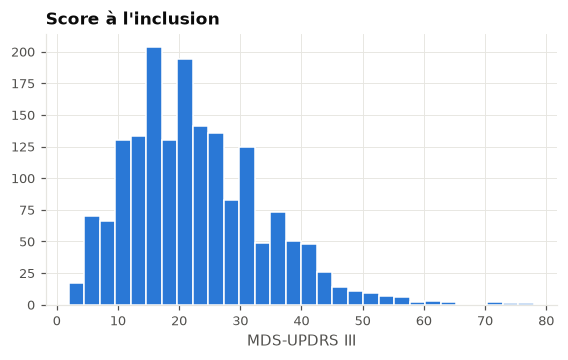

In [10]:
x = bl[bl.PATNO.isin(pd_ids)].np3
print(f"MDS-UPDRS III à l'inclusion : n = {len(x)}, moyenne {x.mean():.1f} ± {x.std():.1f}, "
      f"médiane {x.median():.0f} [{x.quantile(.25):.0f}–{x.quantile(.75):.0f}]")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(x, bins=30, color=viz.C["blue"], edgecolor="white"); ax.set_title("Score à l'inclusion"); ax.set_xlabel("MDS-UPDRS III")
viz.save(fig, FIG, "06_distribution_bl"); plt.show()

**Observation.** Distribution à une bosse, un peu asymétrique à droite : pas exactement normale.

**Décision.** Description en médiane [IQR] et tests **non paramétriques** pour les comparaisons simples. Pour les
modèles mixtes, ce qui compte est la normalité des **résidus** (à vérifier sur les résidus du modèle mixte).

### 5.2 Trajectoires individuelles

In [ ]:
v = valid[valid.months >= 0].copy()
v["annee"] = (v.months / 12).round()
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for pid in rng.choice(v.PATNO.unique(), 40, replace=False):          # 40 patients au hasard, sans identifiant
    d = v[(v.PATNO == pid) & v.state.isin(["untreated", "OFF"])].sort_values("months")
    axes[0].plot(d.months / 12, d.np3, color=viz.C["blue"], alpha=.35, lw=1)
axes[0].set_title("40 trajectoires individuelles"); axes[0].set_xlabel("années"); axes[0].set_ylabel("MDS-UPDRS III")
for s, label in [("untreated", "sans traitement"), ("OFF", "OFF"), ("ON", "ON")]:
    d = v[v.state.eq(s) & v.annee.le(12)].groupby("annee").np3.agg(["mean", "sem", "size"])
    d = d[d["size"] >= 20]
    axes[1].plot(d.index, d["mean"], marker="o", color=viz.MED_COLORS[s], label=label)
    axes[1].fill_between(d.index, d["mean"] - 1.96 * d["sem"], d["mean"] + 1.96 * d["sem"],
                         color=viz.MED_COLORS[s], alpha=.15, lw=0)
axes[1].legend(title="état de l'examen"); axes[1].set_title("Moyenne par année (IC 95 %)"); axes[1].set_xlabel("années")
viz.save(fig, FIG, "06_trajectoires"); plt.show()

**Observation.** Les trajectoires sont très **différentes** d'un patient à l'autre et **bruitées** d'une visite à
l'autre. La moyenne augmente avec le temps, à un niveau qui dépend de l'état de l'examen.

**Pour les modèles.** Il faut une **pente propre à chaque patient** (effet aléatoire) : c'est exactement la question
de l'objectif 3. Le bruit entre visites rend la référence « le score ne change pas » (persistance) difficile à battre.

### 5.3 Les visites d'un même patient se ressemblent (ICC)

In [11]:
import statsmodels.formula.api as smf
d = v[v.state.isin(["untreated", "OFF"])]
m0 = smf.mixedlm("np3 ~ 1", d, groups=d["PATNO"]).fit(reml=True)
var_entre, var_intra = float(m0.cov_re.iloc[0, 0]), float(m0.scale)
print(f"Variance entre patients {var_entre:.1f} | au sein d'un patient {var_intra:.1f} | "
      f"ICC = {var_entre / (var_entre + var_intra):.2f}")

Variance entre patients 84.4 | au sein d'un patient 82.8 | ICC = 0.50


**Observation.** Environ la moitié de la variance est **entre patients** (ICC proche de 0,5) : deux visites d'un
même patient ne sont pas indépendantes.

**Décision D9.** Séparation entraînement / test **par patient**, avant toute préparation, et validation croisée
**groupée par patient**. Un découpage ligne par ligne mettrait le même patient des deux côtés et donnerait des
résultats trop optimistes (fuite).

**Pour les modèles.** Les tests statistiques classiques (qui supposent des observations indépendantes) ne
conviennent pas : on utilise des **modèles mixtes**, et des intervalles de confiance par bootstrap **sur les
patients**.

## 6. Les autres modalités et les autres échelles

### 6.1 Quelle part des patients a chaque type de données ?

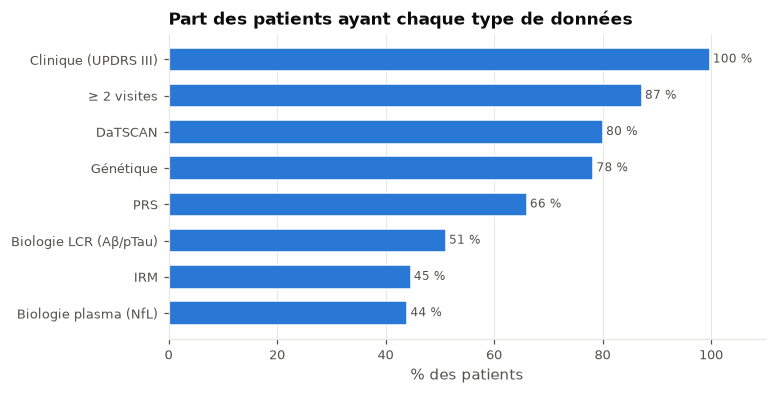

In [12]:
from parkinson_mm.data.biology import baseline_markers
dat = T["datscan"]; dat = dat[dat.DATSCAN_ANALYZED.eq("Yes") & dat.DATSCAN_LIGAND.eq("123I-DaTscan")]
bio = baseline_markers(T["biospecimen"]) if "biospecimen" in T else pd.DataFrame(columns=["PATNO"])
avail = pd.DataFrame({"PATNO": pd_ids.unique()})
for label, ids in {
        "Clinique (UPDRS III)": valid.PATNO, "≥ 2 visites": per_pat.index[per_pat.visites >= 2],
        "DaTSCAN": dat.PATNO, "IRM": T["mri_aseg"].PATNO, "Génétique": T["genetics"].PATNO, "PRS": T["prs"].PATNO,
        "Biologie LCR (Aβ/pTau)": bio.dropna(subset=["csf_abeta42"]).PATNO if "csf_abeta42" in bio else [],
        "Biologie plasma (NfL)": bio.dropna(subset=["plasma_nfl"]).PATNO if "plasma_nfl" in bio else []}.items():
    avail[label] = avail.PATNO.isin(ids)
couverture = (avail.drop(columns="PATNO").mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
viz.bar(ax, couverture.index, couverture.values, horizontal=True, fmt="{:.0f} %")
ax.set_xlim(0, 110); ax.set_title("Part des patients ayant chaque type de données"); ax.set_xlabel("% des patients")
viz.save(fig, FIG, "11_couverture_modalites"); plt.show()

**Observation.** La clinique est complète, mais l'imagerie, la biologie et la génétique ne concernent qu'une partie
des patients (sous-études).

**Décisions D11 à D14, D17, D21, D22.**

| Modalité | Décision | Pourquoi |
|---|---|---|
| DaTSCAN | ligand ¹²³I seulement ; à chaque visite, le **dernier scan déjà fait** | jamais une mesure future (fuite) ; une seule échelle |
| IRM | volumes à l'inclusion, divisés par le volume intracrânien | comparer des cerveaux de tailles différentes |
| Biologie | un seul laboratoire par marqueur, mesure à l'inclusion | mélanger des laboratoires = mélanger des échelles |
| Génétique | porteurs LRRK2 / GBA, APOE ε4, score polygénique | variables fixes du patient |
| Smartphone, capteurs | hors des modèles | environ 1 % des patients |

**Pour les modèles.** Une modalité n'est jamais imposée à tous : chaque facteur est étudié sur les patients qui
l'ont (objectif 3), et un indicateur « valeur manquante » accompagne chaque variable dans les réseaux.

### 6.2 Les échelles cliniques sont-elles redondantes ?

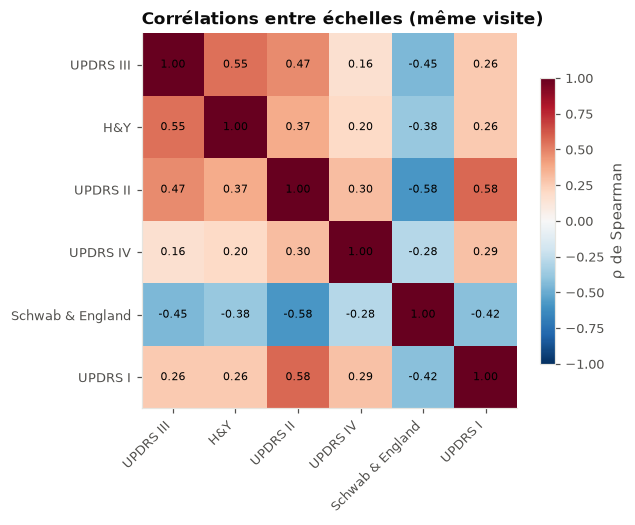

In [13]:
def visit_scores(key, col):
    d = T[key][["PATNO", "EVENT_ID", col]].copy()
    d[col] = pd.to_numeric(d[col], errors="coerce").where(lambda s: s < 101)
    return d.groupby(["PATNO", "EVENT_ID"], as_index=False)[col].mean()

one = (valid.assign(rang=valid.state.map(RANG))
       .sort_values("rang").drop_duplicates(["PATNO", "EVENT_ID"])[["PATNO", "EVENT_ID", "np3", "nhy"]])
for key, col in {"updrs1": "NP1RTOT", "updrs1p": "NP1PTOT", "updrs2": "NP2PTOT", "updrs4": "NP4TOT",
                 "schwab": "MSEADLG"}.items():
    if key in T:
        one = one.merge(visit_scores(key, col), on=["PATNO", "EVENT_ID"], how="left")
one["updrs1"] = one.get("NP1RTOT") + one.get("NP1PTOT", 0)           # UPDRS I = partie évaluateur + patient
one = one.drop(columns=["NP1RTOT", "NP1PTOT"], errors="ignore")
noms = {"np3": "UPDRS III", "nhy": "H&Y", "updrs1": "UPDRS I", "NP2PTOT": "UPDRS II", "NP4TOT": "UPDRS IV",
        "MSEADLG": "Schwab & England"}
corr = one.drop(columns=["PATNO", "EVENT_ID"]).rename(columns=noms).corr("spearman")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap=viz.DIV, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7.5)
fig.colorbar(im, ax=ax, shrink=.75, label="ρ de Spearman"); ax.set_title("Corrélations entre échelles (même visite)")
viz.save(fig, FIG, "07_correlations_echelles"); plt.show()

**Observation.** Les échelles sont liées entre elles (corrélations modérées, Spearman car les scores ne sont pas
normaux) mais **pas redondantes** : aucune paire n'est proche de 1.

**Décision D10.** On garde ces échelles comme entrées (seulement leurs valeurs passées), sans risque de doublon : c'est la base de la
**sélection de variables a priori** expliquée dans `02_nettoyage.ipynb`.

## 7. Données manquantes et abandons

### 7.1 Manquants par année de suivi

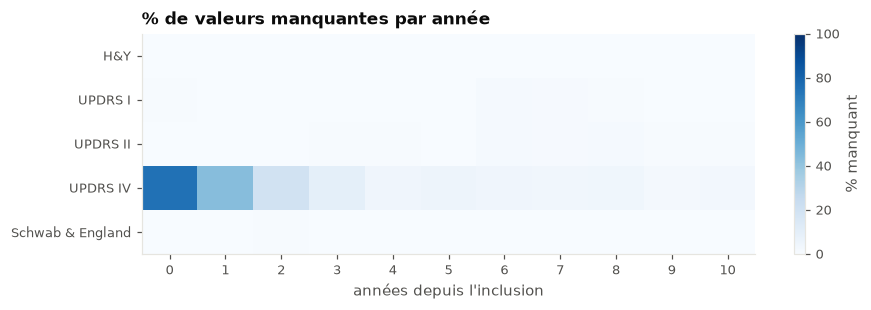

In [14]:
one = one.merge(v[["PATNO", "EVENT_ID", "annee"]].drop_duplicates(["PATNO", "EVENT_ID"]), on=["PATNO", "EVENT_ID"])
cols = [c for c in ["nhy", "updrs1", "NP2PTOT", "NP4TOT", "MSEADLG"] if c in one]
miss = one[one.annee <= 10].groupby("annee")[cols].apply(lambda d: d.isna().mean() * 100).rename(columns=noms)
fig, ax = plt.subplots(figsize=(9, 2.6))
im = ax.imshow(miss.T, cmap=viz.SEQ, vmin=0, vmax=100, aspect="auto"); ax.grid(False)
ax.set_xticks(range(len(miss)), [int(i) for i in miss.index]); ax.set_yticks(range(miss.shape[1]), miss.columns)
ax.set_xlabel("années depuis l'inclusion"); ax.set_title("% de valeurs manquantes par année")
fig.colorbar(im, ax=ax, label="% manquant"); viz.save(fig, FIG, "11_manquants_par_annee"); plt.show()

**Observation.** Les échelles sont presque complètes quand l'examen moteur existe. L'UPDRS IV (complications du
traitement) manque surtout au début : il n'a de sens que chez les patients traités. Le manquant est donc
**structurel**, pas aléatoire.

### 7.2 Les patients qui partent sont-ils différents ?

In [15]:
pp = per_pat.join(bl.set_index("PATNO").np3).join(st.set_index("PATNO").ENROLL_STATUS)       # patients PD
pp["suivi"] = pd.cut(pp.suivi_ans, [-.1, 2, 5, 20], labels=["≤ 2 ans", "2–5 ans", "> 5 ans"])
display(pp.groupby("suivi", observed=True).np3.describe()[["count", "mean", "50%"]].round(1))
groupes = [g.np3.dropna() for _, g in pp.groupby("suivi", observed=True)]
print("Score à l'inclusion selon la durée de suivi : Kruskal-Wallis p =", f"{stats.kruskal(*groupes).pvalue:.1e}")

,count,mean,50%
suivi,,,
≤ 2 ans,571.0,24.4,23.0
2–5 ans,656.0,22.9,21.0
> 5 ans,506.0,20.7,19.0


Score à l'inclusion selon la durée de suivi : Kruskal-Wallis p = 2.6e-06


**Observation.** Les patients suivis peu longtemps ont un score un peu plus élevé à l'inclusion. Une partie vient du
recrutement (patients récents de PPMI 2.0, suivi court par construction), mais une **attrition informative** est
possible (des patients qui s'aggravent quittent l'étude).

**Décisions D15 et D16.** Pas d'imputation de la cible. Les modèles mixtes utilisent toutes les visites disponibles : ils
supposent que les données manquent « au hasard » une fois les données observées prises en compte (**MAR**). Cette
hypothèse ne se vérifie pas avec un seul test : on la discute, et on refait l'analyse sur les patients suivis au
moins 5 ans (analyse de sensibilité). Pour la prédiction, l'imputation est apprise **sur le jeu d'entraînement
seulement**, avec un indicateur de valeur manquante.

## 8. Synthèse : des observations aux décisions

| # | Observation | Décision | Conséquence pour les modèles |
|---|---|---|---|
| D1 | Doublons (patient, visite) dans l'UPDRS III | les résoudre avant toute jointure | pas de lignes multipliées |
| D2 | Base surtout prodromale ; des PD jamais suivis | PD réellement inclus, retraits gardés | pas de biais du survivant |
| D4–D5 | Visites irrégulières, attrition | temps continu en années | modèles mixtes ; écart de temps en entrée du GRU-D |
| D6–D7 | Code 101, totaux manquants, visites à distance | 101 → manquant ; proratisation si ≤ 3 items ; R## exclues | cible propre, entre 0 et 132 |
| D8 | Écart OFF − ON d'environ 10 points | un examen par visite (sans traitement > OFF > ON) ; état en variable | état prévu en entrée de tous les modèles |
| D9 | ICC élevé (≈ 0,5 dans PPMI) | split et validation croisée **par patient** | aucune fuite entre patients |
| D10 | Échelles liées mais non redondantes | garder leurs valeurs passées comme entrées | sélection de variables a priori |
| D11–D14, D17, D21, D22 | Modalités partielles (sous-études) | règles par modalité ; DaTSCAN « dernier scan passé » | facteur par facteur ; indicateurs de manquant |
| D15–D16 | Manquants structurels, attrition possiblement informative | pas d'imputation de la cible ; imputation apprise sur le train | masques du GRU-D ; sensibilité ≥ 5 ans |

Les autres décisions de la liste D1–D22 (ajustement sur l'âge et le sexe D3, durée de maladie D18, dose de
lévodopa D19, échelles non motrices D20) sont décrites dans `docs/sprints/01_sprint1_donnees.md`.

La suite : `02_nettoyage.ipynb` montre comment ces décisions sont appliquées, vérifiées et transformées en variables
pour les modèles.